# Teks — Klasifikasi dengan Embedding Kalimat (pretrained, dibekukan)
**Kapan dipakai:** TF-IDF kurang menangkap makna (sinonim, kalimat beda kata tapi maksud
sama), tetapi tidak ada waktu/GPU untuk fine-tuning.

**Langkah:** model pretrained mengubah tiap teks menjadi vektor angka (sekali saja) →
classifier sklearn biasa → F1 macro.

**Data demo:** SmSA (sentimen Bahasa Indonesia). Model embedding: MiniLM multibahasa lokal.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
from lightgbm import LGBMClassifier
from sentence_transformers import SentenceTransformer
from sklearn.linear_model import LogisticRegression, RidgeClassifier
from sklearn.metrics import ConfusionMatrixDisplay, classification_report, f1_score
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC, LinearSVC

## Konfigurasi

In [2]:
DATA_FOLDER = "../../data_latihan/text/sentiment"   # GANTI saat lomba
TRAIN_CSV = f"{DATA_FOLDER}/smsa_train.csv"
TEST_CSV = f"{DATA_FOLDER}/smsa_test.csv"

EMBEDDING_MODEL = "../../pretrained/minilm"
# EMBEDDING_MODEL = "../../pretrained/indobert"        # khusus Indonesia
# EMBEDDING_MODEL = "../../pretrained/distilbert_id"   # lebih ringan
# EMBEDDING_MODEL = "../../pretrained/minilm_en"       # teks bahasa Inggris

TEXT_COL = "text"
TARGET = "label"
BATCH_SIZE = 64
SEED = 42

## Baca data

In [3]:
train = pd.read_csv(TRAIN_CSV)
test = pd.read_csv(TEST_CSV)
train[TEXT_COL] = train[TEXT_COL].fillna("")
test[TEXT_COL] = test[TEXT_COL].fillna("")
print("train:", train.shape, "| test:", test.shape)
train.head()

train: (5148, 3) | test: (1260, 2)


,id,text,label
0,1,kenapa lumayan enak ? karena ada sushi lain ya...,negative
1,2,berarti staff nya anies yang tidak becus mengu...,negative
2,3,orang cina makanan legendaris sudah lama bange...,negative
3,4,"mental apa ini pak jokowi , bagaimana ini pak ...",negative
4,5,selama iblis binatang ini jadi kapolri jangan ...,negative


## EDA: jumlah per kelas dan panjang teks

label
negative    2000
positive    2000
neutral     1148
Name: count, dtype: int64


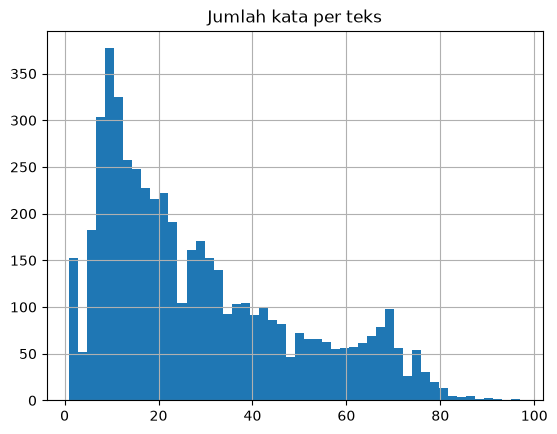

In [4]:
print(train[TARGET].value_counts())
word_counts = train[TEXT_COL].str.split().str.len()
word_counts.hist(bins=50)
plt.title("Jumlah kata per teks")
plt.show()

## Embedding
Teks diubah jadi vektor sekali di awal. Model embedding tidak dilatih ulang.

In [5]:
encoder = SentenceTransformer(EMBEDDING_MODEL)
train_vectors = encoder.encode(list(train[TEXT_COL]), batch_size=BATCH_SIZE,
                               show_progress_bar=True)
test_vectors = encoder.encode(list(test[TEXT_COL]), batch_size=BATCH_SIZE,
                              show_progress_bar=True)
print("train:", train_vectors.shape, "| test:", test_vectors.shape)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Batches:   0%|          | 0/81 [00:00<?, ?it/s]

Batches:   0%|          | 0/20 [00:00<?, ?it/s]

train: (5148, 384) | test: (1260, 384)


## Split train / validasi

In [6]:
X_train, X_val, y_train, y_val = train_test_split(
    train_vectors, train[TARGET], test_size=0.2, stratify=train[TARGET], random_state=SEED
)

## Model
Pilih SATU model: hapus `#` di baris yang ingin dipakai, beri `#` pada baris lain.

In [7]:
model = LogisticRegression(C=1.0, max_iter=2000)                 # cepat, mudah dijelaskan
# model = LinearSVC(C=0.5)
# model = KNeighborsClassifier(n_neighbors=15, metric="cosine")
# model = MLPClassifier(hidden_layer_sizes=(256,), max_iter=300, random_state=SEED)
# model = SVC(C=10, random_state=SEED)
# model = RidgeClassifier(alpha=1.0)
# model = LGBMClassifier(n_estimators=300, verbose=-1, random_state=SEED)

pipe = make_pipeline(StandardScaler(), model)
pipe.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('standardscaler', ...), ('logisticregression', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[object](3,)","['negative','neutral','positive']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,384
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
Name,Type,Value


## Evaluasi di validasi

F1 macro: 0.8461
              precision    recall  f1-score   support

    negative       0.86      0.83      0.85       400
     neutral       0.81      0.80      0.81       230
    positive       0.86      0.90      0.88       400

    accuracy                           0.85      1030
   macro avg       0.85      0.85      0.85      1030
weighted avg       0.85      0.85      0.85      1030



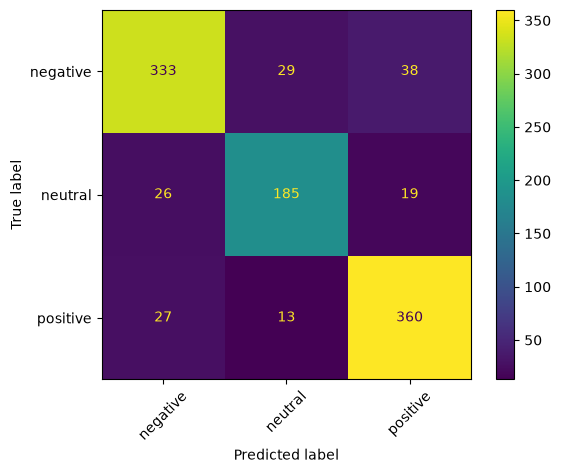

In [8]:
val_predictions = pipe.predict(X_val)
print("F1 macro:", round(f1_score(y_val, val_predictions, average="macro"), 4))
# soal 2 kelas: print("F1:", f1_score(y_val, val_predictions, pos_label="isi_kelas_positif"))
print(classification_report(y_val, val_predictions))
ConfusionMatrixDisplay.from_predictions(y_val, val_predictions, xticks_rotation=45)
plt.show()

## Latih ulang di semua data + submission

In [9]:
pipe.fit(train_vectors, train[TARGET])
predictions = pipe.predict(test_vectors)

submission = pd.DataFrame()
submission["id"] = test["id"]
submission["label"] = predictions
submission.to_csv("submission.csv", index=False)
submission.head()

,id,label
0,100001,neutral
1,100002,negative
2,100003,positive
3,100004,positive
4,100005,negative
